# London (TfL) — Benchmark City for EMT Madrid Bus Electrification

**IE Sustainability Datathon 2026 · Kearney challenge: Zero-Emission Urban Bus Fleets**

**Question this notebook answers:** what is London doing right on **depots, grid and routes**, and what should Madrid copy, adapt or avoid?

London runs the largest zero-emission bus fleet in Western Europe: 2,957 zero-emission buses out of 8,982 (31 Mar 2026), across 77 garages. TfL does not run buses itself. It tenders each route to private operators on 7-year contracts, and the operators own the garages, the buses, the chargers and the grid connections.

**Sections**
1. Fleet transition 2013–2026
2. Garages: size, electric share, and why London's grid problem is smaller than Madrid's
3. Routes: daily duty per bus, and which routes need terminal charging
4. Grid: energy and power per garage at 100% electric, vs real London connections
5. Contracts: how tenders drive the transition, and what electric contracts cost
6. Map
7. Three-city comparison (Madrid · Brussels · London)
8. **Propositions for Madrid**

**Data sources**
| Data | Source |
|---|---|
| Fleet by type, 2013–2026; fleet audit 31 Mar 2026 | TfL Bus fleet audit; `tfl buses type.csv` (London Datastore) |
| Routes: garage, operator, PVR, deck, propulsion, contract awards | `route_classifications.json`, londonbuses.org pipeline (TfL Unified API, TfL iBus, DVLA, londonbusroutes.net, TfL tender results) |
| Garages with coordinates | `garage-locations.json` (same pipeline, geocoded) |
| Bus-km operated per route, 2025/26 | TfL annual bus statistics |
| Route geometry | TfL Route Geometry feed (14 Nov 2026) |
| Real garage grid connections | UK Power Networks press; operator, Zenobē and architect case studies (via NotebookLM research brief) |
| Madrid model | `../Madrid/outputs/File_2.csv` |

**Caveats:** route propulsion is the *majority* vehicle type seen on each route (DVLA lookups of observed buses), so mixed routes count as one type. Fleet totals therefore come from the official audit. London publishes no network-wide timetable here, so there is **no hourly vehicle profile**: the night charging window is an input.

In [1]:
# ===================== INPUTS =====================
DATA, OUT = "data", "outputs"
MADRID_FILE2 = "../Madrid/outputs/File_2.csv"

DAY_TYPES = ["regular", "twentyfour"]        # routes whose PVR counts toward the peak fleet
KWH_KM = {"single": 1.00, "double": 1.30}    # London 10–11 m single-deck / 10.9 m double-deck (assumption)
WINTER_UPLIFT = 0.25                         # heating on cold days
USABLE_BATTERY_KWH = {"single": 280, "double": 320}  # e.g. 382 kWh LFP double-deck pack, ~85% usable (assumption)
NIGHT_HOURS = 6.0       # overnight charging window (London runs many 24h routes; Madrid model used 6.4 h)
LOSS_FACTOR = 1.10
MIN_PVR = 3             # ignore tiny routes when ranking duty (PVR noise)

# Real London grid connections (kVA) and e-buses served: UKPN, operator & case-study sources
REAL_GRID = [
    # garage name in data, kVA, e-buses, source / note
    ("Waterloo",  2000,  46, "UKPN / routeone; first all-electric garage (2016)"),
    ("Walworth",  1000,  34, "UK Power Networks: new 1,000 kVA transformer, routes C10 + P5"),
    ("Fulwell",   3000,  75, "Janus Architecture: new 3 MW HV supply (RATP Dev, now First)"),
    ("Battersea", 5000,  48, "Zenobē case study: 5 MVA"),
    ("Southall",   500,  25, "Zenobē: constrained 500 kVA + 1.2 MW / 1.2 MWh battery storage"),
]
GOAHEAD_NEW_DEPOT = (10000, 200)   # Bus & Coach Buyer: planned 10 MVA for 200 e-buses

# Brussels figures from ../Brussels/brussels_benchmark_full.ipynb
BXL = {"depots": 5, "fleet": 850, "peak": 616, "km_bus_day": 148.8, "kva_per_bus_real": 95, "mw_night": 26.8}
# ==================================================

import os, json, zipfile, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

os.makedirs(OUT, exist_ok=True)
pd.set_option("display.width", 170)
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e5e1", "#b4b3ad"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False,
})
PROP_COL = {"electric": C1, "hybrid": C3, "diesel": C2, "hydrogen": C4}

## 0. Load and join the data

In [2]:
%pip install openpyxl
R = pd.DataFrame.from_dict(json.load(open(f"{DATA}/route_classifications.json"))["routes"], orient="index")
R.index = R.index.astype(str).str.upper()
G = pd.DataFrame.from_dict(json.load(open(f"{DATA}/garage-locations.json"))["garages"], orient="index")
for c in ["pvr", "fleetSize", "currentContractCostPerMile", "contractTermYears"]:
    R[c] = pd.to_numeric(R[c], errors="coerce")

km = pd.read_excel(f"{DATA}/2025-26-annual-bus-stats.xlsx", sheet_name="2025-2026", header=2)
km.columns = ["route", "boardings", "km_year", "note"]
km["route"] = km.route.astype(str).str.strip().str.upper()
km = km[pd.to_numeric(km.km_year, errors="coerce").notna()].astype({"km_year": float, "boardings": float})
R = R.join(km.set_index("route")[["km_year", "boardings"]])

day = R[R.type.isin(DAY_TYPES)].copy()
print(f"Routes: {len(R)} ({len(day)} day/24h) | with annual km: {R.km_year.notna().sum()} | garages: {len(G)}")
print(f"Annual bus-km (all routes in file): {R.km_year.sum() / 1e6:.0f} M | day-route PVR: {day.pvr.sum():,.0f}")


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Routes: 677 (545 day/24h) | with annual km: 605 | garages: 77
Annual bus-km (all routes in file): 450 M | day-route PVR: 7,202


## 1. Fleet transition 2013–2026

London's path runs **diesel → hybrid (bridge) → battery-electric**, like Brussels. Since 2021 every new bus entering the fleet has been zero-emission. Hybrids are not being renewed, and their number has been falling since 2021.

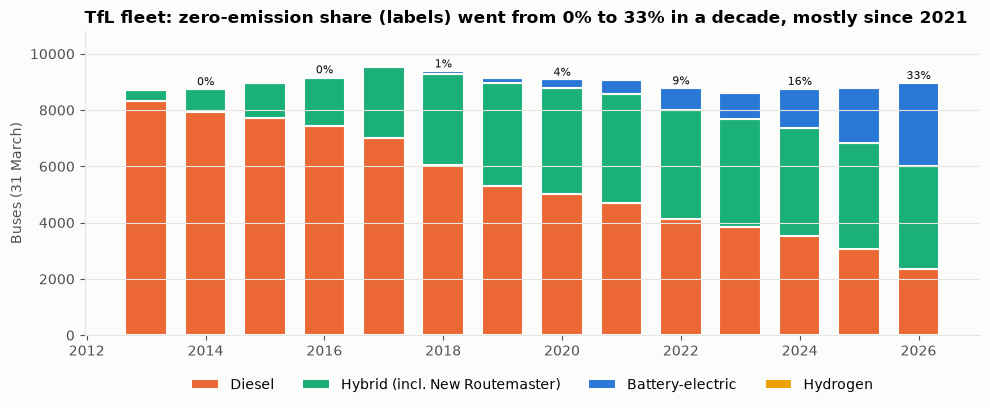

cat,diesel,hybrid,electric,hydrogen,zero_emission_%
year,,,,,
2021,4697,3884,485,2,5.4
2022,4134,3854,785,22,9.2
2023,3838,3835,950,20,11.2
2024,3532,3826,1398,20,16.2
2025,3049,3776,1952,20,22.4
2026,2357,3668,2937,20,32.9


In [3]:
ft = pd.read_csv(f"{DATA}/tfl buses type.csv")
ft["n"] = pd.to_numeric(ft.number_of_buses.astype(str).str.replace(",", "").replace("-", "0"), errors="coerce").fillna(0)
ft["cat"] = ft.drive_train_type.map(lambda s: "electric" if s.startswith("electric")
                                    else "hydrogen" if s == "fuel_cell" else "hybrid" if s.startswith("hybrid") else "diesel")
mix = ft.pivot_table(index="year", columns="cat", values="n", aggfunc="sum").fillna(0)[["diesel", "hybrid", "electric", "hydrogen"]]
mix["zero_emission_%"] = (100 * (mix.electric + mix.hydrogen) / mix.sum(axis=1)).round(1)

fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = np.zeros(len(mix))
for col, lab in [("diesel", "Diesel"), ("hybrid", "Hybrid (incl. New Routemaster)"), ("electric", "Battery-electric"), ("hydrogen", "Hydrogen")]:
    ax.bar(mix.index, mix[col], bottom=bottom, color=PROP_COL[col], width=0.7, label=lab, edgecolor="#fcfcfb", linewidth=1.5)
    bottom += mix[col].values
for x, (tot, z) in zip(mix.index, zip(bottom, mix["zero_emission_%"])):
    if x % 2 == 0 or x == mix.index.max():
        ax.text(x, tot + 120, f"{z:.0f}%", ha="center", fontsize=8, color=INK)
ax.set_ylabel("Buses (31 March)"); ax.set_ylim(0, 10800); ax.grid(axis="x", visible=False)
ax.set_title("TfL fleet: zero-emission share (labels) went from 0% to 33% in a decade, mostly since 2021")
ax.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout(); fig.savefig(f"{OUT}/fig_london_fleet_transition.png", dpi=160); plt.show()
mix.astype({c: int for c in ["diesel", "hybrid", "electric", "hydrogen"]}).tail(6)

## 2. Garages: many small sites instead of a few big ones

The key structural difference for the grid: London spreads ~7,400 peak buses over **77 garages**, while Madrid concentrates ~2,000 into **5 depots**. Each Madrid depot needs a grid connection of the size London uses for its very largest sites, and those big connections are the ones with 3–10 year lead times.

In [4]:
day["is_e"] = day.propulsion.eq("electric")
gar = day.groupby("garageCode").agg(
    routes=("pvr", "size"), pvr=("pvr", "sum"),
    e_pvr=("pvr", lambda s: s[day.loc[s.index, "is_e"]].sum()),
    operator=("operator", lambda s: s.mode().iat[0] if len(s.mode()) else None))
allkm = R.groupby("garageCode").km_year.sum()
# energy at 100% electric: km per route x deck-specific kWh/km, all route types (night/school buses come from the same garage)
R["kwh_km"] = R.deck.map(KWH_KM).fillna(KWH_KM["double"])
gar["mwh_day_100e"] = (R.km_year * R.kwh_km).groupby(R.garageCode).sum() / 365 / 1000
gar = gar.join(G[["name", "lat", "lon", "capacity"]])
gar["e_share_%"] = (100 * gar.e_pvr / gar.pvr).round(0)
gar["mw_needed_100e"] = gar.mwh_day_100e / NIGHT_HOURS * LOSS_FACTOR
gar["kw_per_bus_needed"] = 1000 * gar.mw_needed_100e / gar.pvr
gar = gar[gar.pvr > 0].sort_values("pvr", ascending=False)

print(f"Garages with day routes: {len(gar)} | median peak buses per garage: {gar.pvr.median():.0f} "
      f"(max {gar.pvr.max():.0f}, {gar.name.iloc[0]})")
print(f"Median grid power needed per garage at 100% electric: {gar.mw_needed_100e.median():.1f} MW "
      f"(max {gar.mw_needed_100e.max():.1f} MW)")
print(f"Garages already majority-electric by PVR: {(gar['e_share_%'] >= 50).sum()} | fully electric: {(gar['e_share_%'] >= 99).sum()}")

ops = day.groupby("operator").agg(pvr=("pvr", "sum"), e_pvr=("pvr", lambda s: s[day.loc[s.index, "is_e"]].sum()),
                                   garages=("garageCode", "nunique"))
ops["e_share_%"] = (100 * ops.e_pvr / ops.pvr).round(0)
gar.to_csv(f"{OUT}/london_garages_energy.csv")
ops.sort_values("pvr", ascending=False)

Garages with day routes: 76 | median peak buses per garage: 91 (max 215, Battersea)
Median grid power needed per garage at 100% electric: 3.5 MW (max 7.1 MW)
Garages already majority-electric by PVR: 28 | fully electric: 8


,pvr,e_pvr,garages,e_share_%
operator,,,,
Go-Ahead,1937.0,977.0,17,50.0
Metroline,1235.0,492.0,14,40.0
Stagecoach London,1229.0,414.0,13,34.0
Arriva,1147.0,444.0,15,39.0
First,825.0,402.0,9,49.0
Transport UK,816.0,340.0,6,42.0
Uno,11.0,3.0,1,27.0
Falcon Coaches,2.0,0.0,1,0.0


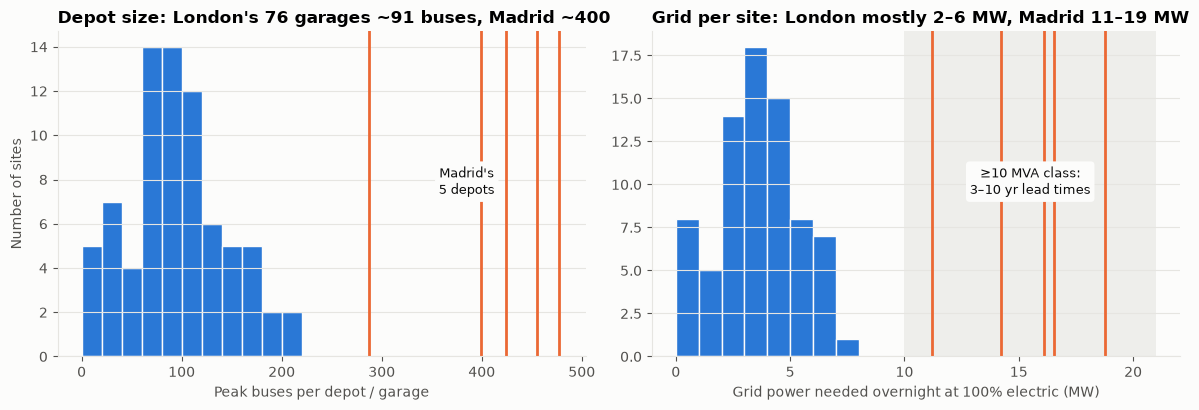

,buses,mwh,mw
depot_name,,,
Carabanchel,455,93.6,16.1
Entrevías,399,82.7,14.2
Fuencarral,477,96.3,16.6
La Elipa,287,65.3,11.2
Sanchinarro,424,109.3,18.8


In [5]:
m = pd.read_csv(MADRID_FILE2)
mad_dep = m.groupby("depot_name").agg(buses=("peak_buses", "sum"),
                                      mwh=("energy_kwh_bus_day", lambda s: (s * m.loc[s.index, "peak_buses"]).sum() / 1000))
mad_dep["mw"] = mad_dep.mwh / 6.4 * LOSS_FACTOR

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.hist(gar.pvr, bins=range(0, 500, 20), color=C1, edgecolor="#fcfcfb", label=f"London garages (n={len(gar)})")
for b, n_ in zip(mad_dep.buses, mad_dep.index):
    ax.axvline(b, color=C2, lw=2)
ax.text(385, ax.get_ylim()[1] * 0.5, "Madrid's\n5 depots", ha="center", color=INK, fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", fc="#fcfcfb", ec="none"))
ax.set_xlabel("Peak buses per depot / garage"); ax.set_ylabel("Number of sites"); ax.grid(axis="x", visible=False)
ax.set_title(f"Depot size: London's {len(gar)} garages ~{gar.pvr.median():.0f} buses, Madrid ~400")
ax = axes[1]
ax.hist(gar.mw_needed_100e, bins=np.arange(0, 21, 1), color=C1, edgecolor="#fcfcfb")
for v in mad_dep.mw:
    ax.axvline(v, color=C2, lw=2)
ax.axvspan(10, 21, color=GRID, alpha=0.6, lw=0)
ax.text(15.5, ax.get_ylim()[1] * 0.5, "≥10 MVA class:\n3–10 yr lead times", ha="center", fontsize=9, color=INK,
        bbox=dict(boxstyle="round,pad=0.3", fc="#fcfcfb", ec="none"))
ax.set_xlabel("Grid power needed overnight at 100% electric (MW)"); ax.grid(axis="x", visible=False)
ax.set_title("Grid per site: London mostly 2–6 MW, Madrid 11–19 MW")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_depot_size_and_power_london_vs_madrid.png", dpi=160); plt.show()
mad_dep.round(1)

## 3. Routes: daily duty per bus, and where terminal charging is needed

Daily km per bus = annual km ÷ 365 ÷ PVR. Energy per bus = km × kWh/km. A route needs **opportunity (terminal) charging** if one bus's daily energy exceeds its usable battery. That's the same logic as the Madrid and Brussels models, with battery limits for London's vehicles.

**Check against reality:** London's flagship terminal-charging route is **358** (Crystal Palace–Orpington, 450 kW pantographs since Nov 2024). If the model does *not* flag it, then London chose terminal charging there to run **small, light, fast-charge batteries** (Irizar ie tram), not because the route is extreme. That's the same pattern STIB showed with its articulated buses in Brussels.

In [6]:
d = day[(day.pvr >= MIN_PVR) & day.km_year.notna()].copy()
d["km_bus_day"] = d.km_year / 365 / d.pvr
d["kwh_bus_day"] = d.km_bus_day * d.deck.map(KWH_KM)
d["limit"] = d.deck.map(USABLE_BATTERY_KWH)
d["opp_base"] = d.kwh_bus_day > d.limit
d["opp_winter"] = d.kwh_bus_day * (1 + WINTER_UPLIFT) > d.limit

print(f"Median km per bus per day: {d.km_bus_day.median():.0f} km (IQR {d.km_bus_day.quantile(.25):.0f}–{d.km_bus_day.quantile(.75):.0f})")
print(f"Routes over battery limit: base {d.opp_base.sum()} ({d.loc[d.opp_base, 'pvr'].sum():.0f} buses) | "
      f"winter {d.opp_winter.sum()} ({d.loc[d.opp_winter, 'pvr'].sum():.0f} buses) of {len(d)} routes")
if "358" in d.index:
    r358 = d.loc["358"]
    print(f"Route 358: {r358.km_bus_day:.0f} km/bus/day, {r358.kwh_bus_day:.0f} kWh vs {r358.limit} kWh {r358.deck}-deck limit "
          f"-> over limit: base {bool(r358.opp_base)}, winter {bool(r358.opp_winter)}")
d.sort_values("kwh_bus_day", ascending=False)[["garageName", "operator", "deck", "propulsion", "pvr", "km_bus_day",
                                               "kwh_bus_day", "opp_base", "opp_winter"]].head(15).round(0)

Median km per bus per day: 167 km (IQR 147–195)
Routes over battery limit: base 11 (117 buses) | winter 87 (1011 buses) of 527 routes
Route 358: 208 km/bus/day, 208 kWh vs 280.0 kWh single-deck limit -> over limit: base False, winter False


,garageName,operator,deck,propulsion,pvr,km_bus_day,kwh_bus_day,opp_base,opp_winter
292,Hatfield,Uno,double,electric,3.0,470.0,611.0,True,True
80,Sutton,Go-Ahead,double,electric,7.0,448.0,582.0,True,True
363,Walworth,Transport UK,double,hybrid,7.0,298.0,388.0,True,True
483,Athlon Road,Metroline,double,diesel,12.0,282.0,367.0,True,True
38,Clapton,Arriva,double,hybrid,16.0,277.0,360.0,True,True
SL3,Bromley,Stagecoach London,double,electric,15.0,270.0,351.0,True,True
A10,Uxbridge Industrial Estate,Metroline,single,diesel,4.0,345.0,345.0,True,True
222,Uxbridge Industrial Estate,Metroline,double,hybrid,14.0,262.0,341.0,True,True
107,Potters Bar,Metroline,double,hybrid,11.0,256.0,333.0,True,True
370,Grays,Arriva,double,hybrid,13.0,254.0,330.0,True,True


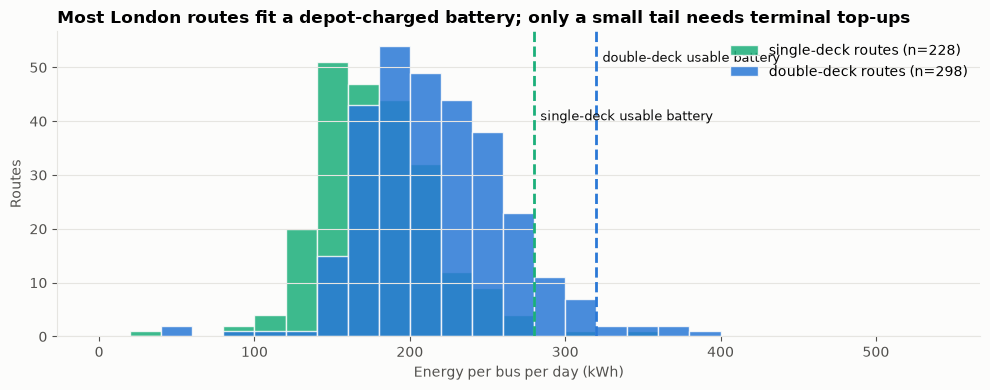

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for deck, col in [("single", C3), ("double", C1)]:
    x = d[d.deck == deck].kwh_bus_day
    ax.hist(x, bins=np.arange(0, 560, 20), color=col, alpha=0.85, label=f"{deck}-deck routes (n={len(x)})",
            edgecolor="#fcfcfb")
    ax.axvline(USABLE_BATTERY_KWH[deck], color=col, ls="--", lw=2)
    ax.text(USABLE_BATTERY_KWH[deck] + 4, ax.get_ylim()[1] * (0.9 if deck == "double" else 0.75),
            f"{deck}-deck usable battery", color=INK, fontsize=9)
ax.set_xlabel("Energy per bus per day (kWh)"); ax.set_ylabel("Routes"); ax.grid(axis="x", visible=False)
ax.set_title("Most London routes fit a depot-charged battery; only a small tail needs terminal top-ups")
ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_london_route_energy.png", dpi=160); plt.show()

## 4. Grid: what London garages need vs what they actually built

For each garage with a published grid connection, we compare:
- **installed:** the real connection (kVA) ÷ the e-buses it serves, and
- **needed:** the overnight power the model says those e-buses require (km and kWh/km of that garage's routes).

When *installed < needed*, the garage relies on **smart charging, staggered charging, battery storage or a longer charging window**.

In [8]:
name2code = {v: k for k, v in G.name.items()}
rows = []
for name, kva, ebus, src in REAL_GRID:
    code_ = next((c for n, c in name2code.items() if n.lower().startswith(name.lower())), None)
    gg = gar.loc[code_] if code_ in gar.index else None
    kw_bus_need = gg.kw_per_bus_needed if gg is not None else np.nan
    rows.append({"garage": name, "code": code_, "real_kVA": kva, "e_buses": ebus,
                 "installed_kVA_per_ebus": round(kva / ebus, 1),
                 "needed_kW_per_bus (model)": round(kw_bus_need, 1),
                 "garage_peak_buses": int(gg.pvr) if gg is not None else None,
                 "kVA_per_bus_if_whole_garage_electric": round(kva / gg.pvr, 1) if gg is not None else None,
                 "source": src})
grid = pd.DataFrame(rows).set_index("garage")
grid.loc["Go-Ahead new depot (planned)"] = [None, GOAHEAD_NEW_DEPOT[0], GOAHEAD_NEW_DEPOT[1],
                                            GOAHEAD_NEW_DEPOT[0] / GOAHEAD_NEW_DEPOT[1], np.nan, None, None,
                                            "Bus & Coach Buyer: 10 MVA for 200 e-buses"]
grid.to_csv(f"{OUT}/london_real_grid_connections.csv")
print(f"London installed grid per e-bus: median {grid.installed_kVA_per_ebus.median():.0f} kVA "
      f"(range {grid.installed_kVA_per_ebus.min():.0f}–{grid.installed_kVA_per_ebus.max():.0f})")
print(f"Model need per bus (overnight {NIGHT_HOURS:.0f} h): London garage median {gar.kw_per_bus_needed.median():.0f} kW")
grid

London installed grid per e-bus: median 42 kVA (range 20–104)
Model need per bus (overnight 6 h): London garage median 37 kW


,code,real_kVA,e_buses,installed_kVA_per_ebus,needed_kW_per_bus (model),garage_peak_buses,kVA_per_bus_if_whole_garage_electric,source
garage,,,,,,,,
Waterloo,RA,2000,46,43.5,23.2,26.0,76.9,UKPN / routeone; first all-electric garage (2016)
Walworth,WL,1000,34,29.4,36.8,147.0,6.8,"UK Power Networks: new 1,000 kVA transformer, ..."
Fulwell,FW,3000,75,40.0,39.8,118.0,25.4,Janus Architecture: new 3 MW HV supply (RATP D...
Battersea,QB,5000,48,104.2,32.2,215.0,23.3,Zenobē case study: 5 MVA
Southall,GW,500,25,20.0,36.2,115.0,4.3,Zenobē: constrained 500 kVA + 1.2 MW / 1.2 MWh...
Go-Ahead new depot (planned),NaN,10000,200,50.0,NaN,NaN,NaN,Bus & Coach Buyer: 10 MVA for 200 e-buses


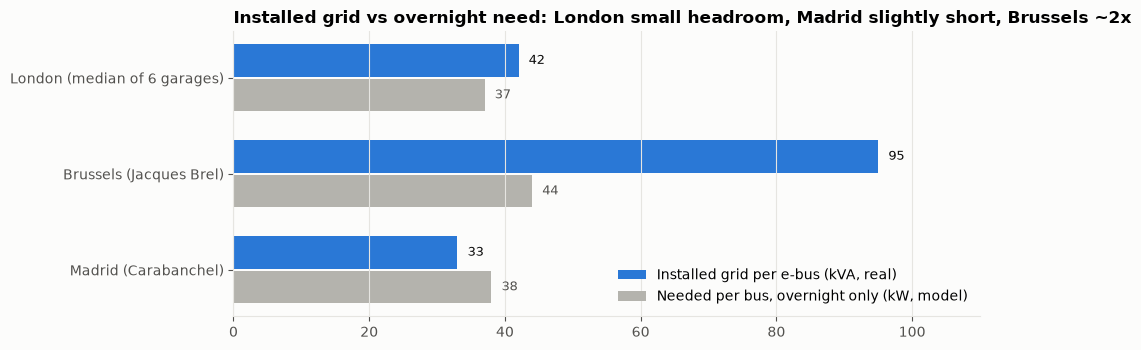

,installed kVA per e-bus (real),needed kW per bus overnight (model)
Madrid (Carabanchel),33.0,38.0
Brussels (Jacques Brel),95.0,44.0
London (median of 6 garages),42.0,37.0


In [9]:
# Three-city grid sizing: installed kVA per bus vs what an overnight-only charge needs
mad_need = 1000 * mad_dep.mw.sum() / mad_dep.buses.sum()
cities = pd.DataFrame({
    "installed kVA per e-bus (real)": [33, BXL["kva_per_bus_real"], grid.installed_kVA_per_ebus.median()],
    "needed kW per bus overnight (model)": [mad_need, 1000 * BXL["mw_night"] / BXL["peak"], gar.kw_per_bus_needed.median()],
}, index=["Madrid (Carabanchel)", "Brussels (Jacques Brel)", "London (median of 6 garages)"]).round(0)

fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(cities))
ax.barh(y + 0.18, cities.iloc[:, 0], height=0.34, color=C1, label="Installed grid per e-bus (kVA, real)")
ax.barh(y - 0.18, cities.iloc[:, 1], height=0.34, color=MUTED, label="Needed per bus, overnight only (kW, model)")
for yi, (a_, b_) in enumerate(cities.values):
    ax.text(a_ + 1.5, yi + 0.18, f"{a_:.0f}", va="center", fontsize=9, color=INK)
    ax.text(b_ + 1.5, yi - 0.18, f"{b_:.0f}", va="center", fontsize=9, color=INK2)
ax.set_yticks(y); ax.set_yticklabels(cities.index); ax.grid(axis="y", visible=False); ax.set_xlim(0, 110)
ax.set_title("Installed grid vs overnight need: London small headroom, Madrid slightly short, Brussels ~2x")
ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_three_city_grid_sizing.png", dpi=160); plt.show()
cities

**How London closes the gap when the grid is short** (research brief, with sources):
- **Battery storage on site:** Southall has a 500 kVA connection plus a 1.2 MW / 1.2 MWh battery for 25 e-buses. Brixton used battery storage to avoid paying for grid reinforcement.
- **Fewer chargers than buses, with software load balancing:** Holloway has 40 chargers for 57 e-buses (BYD smart charging).
- **Install chargers before the high-voltage connection is ready:** Willesden Junction put in 12 chargers first, so the garage could start as soon as power arrived.
- **Charging-as-a-service:** third parties (Zenobē) finance the chargers, batteries and grid works and take the asset risk, which matters when a route contract moves to another operator.
- **Smart overnight charging in cheap off-peak hours:** Waterloo runs 16 hours of service a day with no daytime top-up.
- **Lead times:** large connections (~10 MVA) take **3–10 years**, so they have to be requested years before the buses arrive.

## 5. Contracts: how London actually drives the transition

TfL specifies the propulsion type in each **route tender** (7-year contracts, often with extensions). The electric share of new awards is therefore the real lever, and it shows how fast London can change the fleet.

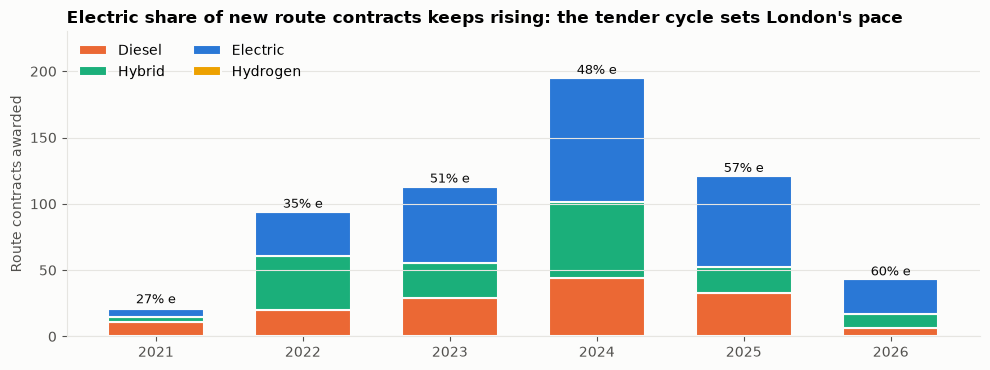

Median contract price per mile (£), awards 2023+:
                                         median  count
currentContractAwardedPropulsion deck                 
diesel                           double    8.63      8
                                 single    8.60     88
electric                         double    9.86    136
                                 single    8.98    102
hybrid                           double    9.13     95
                                 single   10.71      3


currentContractAwardedPropulsion,diesel,electric,hybrid,hydrogen,electric_share_%
award_year,,,,,
2021.0,11,6,4,1,27.0
2022.0,20,33,41,0,35.0
2023.0,29,58,26,0,51.0
2024.0,44,94,57,0,48.0
2025.0,33,69,19,0,57.0
2026.0,6,26,11,0,60.0


In [10]:
R["award_year"] = pd.to_datetime(R.currentContractAwardDate, errors="coerce").dt.year
aw = pd.crosstab(R.award_year, R.currentContractAwardedPropulsion).loc[2021:]
aw["electric_share_%"] = (100 * aw.get("electric", 0) / aw.sum(axis=1)).round(0)

recent = R[(R.award_year >= 2023) & R.currentContractCostPerMile.between(3, 25)]
cost = recent.groupby(["currentContractAwardedPropulsion", "deck"]).currentContractCostPerMile.agg(["median", "count"]).round(2)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = aw.index.astype(int)
bot = np.zeros(len(aw))
for col in ["diesel", "hybrid", "electric", "hydrogen"]:
    if col in aw:
        ax.bar(x, aw[col], bottom=bot, color=PROP_COL[col], width=0.65, label=col.capitalize(),
               edgecolor="#fcfcfb", linewidth=1.5)
        bot += aw[col].values
for xi, tot, sh in zip(x, bot, aw["electric_share_%"]):
    ax.text(xi, tot + 3, f"{sh:.0f}% e", ha="center", fontsize=9, color=INK)
ax.set_ylabel("Route contracts awarded"); ax.grid(axis="x", visible=False); ax.set_ylim(0, bot.max() * 1.18)
ax.set_title("Electric share of new route contracts keeps rising: the tender cycle sets London's pace")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout(); fig.savefig(f"{OUT}/fig_london_contract_awards.png", dpi=160); plt.show()
print("Median contract price per mile (£), awards 2023+:")
print(cost)
aw

## 6. Map: garages and routes by vehicle type

Routes with geometry: 545 of 545


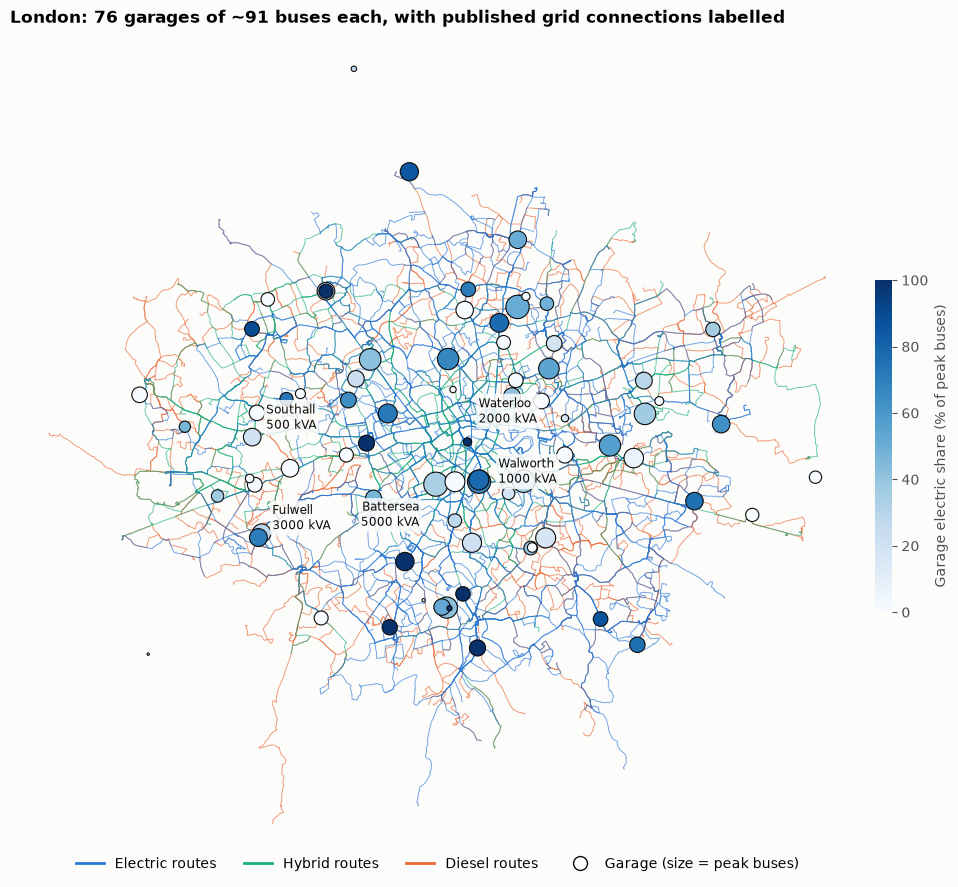

In [11]:
zg = zipfile.ZipFile(f"{DATA}/Route_Geometry_20261114.zip")
pat = re.compile(r'aLBSL_Run_No="1".*?<Direction>1</Direction>.*?<Location_Longitude>([-\d.]+)</Location_Longitude>\s*'
                 r'<Location_Latitude>([-\d.]+)</Location_Latitude>', re.S)
geo = {}
for n in zg.namelist():
    rid = n.split("_")[2].upper()
    if rid in day.index:
        pts = pat.findall(zg.read(n).decode("utf-8", "ignore"))
        if len(pts) > 2:
            geo[rid] = np.array(pts, dtype=float)
print(f"Routes with geometry: {len(geo)} of {len(day)}")

fig, ax = plt.subplots(figsize=(11, 9))
ax.set_aspect(1 / np.cos(np.radians(51.5))); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
for prop in ["diesel", "hybrid", "electric"]:
    for rid in day.index[day.propulsion == prop]:
        if rid in geo:
            ax.plot(geo[rid][:, 0], geo[rid][:, 1], color=PROP_COL[prop], lw=0.7, alpha=0.65, zorder=2)
gg = gar.dropna(subset=["lat"])
sc = ax.scatter(gg.lon, gg.lat, s=gg.pvr * 1.4, c=gg["e_share_%"], cmap="Blues", vmin=0, vmax=100,
                edgecolor=INK, linewidth=0.8, zorder=5)
cb = fig.colorbar(sc, ax=ax, shrink=0.4, pad=0.01); cb.set_label("Garage electric share (% of peak buses)", color=INK2)
cb.outline.set_visible(False)
for n, r in grid.dropna(subset=["code"]).iterrows():
    if r.code in gg.index:
        off = {"Battersea": (-12, -30), "Walworth": (14, -2), "Waterloo": (8, 14)}.get(n, (10, 6))
        ax.annotate(f"{n}\n{int(r.real_kVA)} kVA", (gg.loc[r.code, "lon"], gg.loc[r.code, "lat"]),
                    xytext=off, textcoords="offset points", ha="right" if off[0] < 0 else "left", fontsize=8.5, color=INK, zorder=7,
                    bbox=dict(boxstyle="round,pad=0.2", fc="#fcfcfb", ec="none", alpha=0.85))
ax.legend(handles=[Line2D([], [], color=PROP_COL[p], lw=2, label=f"{p.capitalize()} routes") for p in ["electric", "hybrid", "diesel"]]
          + [Line2D([], [], marker="o", ls="", mfc="white", mec=INK, ms=10, label="Garage (size = peak buses)")],
          loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=4)
ax.set_title(f"London: {len(gg)} garages of ~{gg.pvr.median():.0f} buses each, with published grid connections labelled")
fig.tight_layout(); fig.savefig(f"{OUT}/fig_london_network_map.png", dpi=160); plt.show()

## 7. Three-city comparison

In [12]:
mk = m.daily_km.sum() / m.peak_buses.sum()
three = pd.DataFrame({
    "Madrid (EMT)": {
        "Operating model": "Municipal operator owns depots, buses, chargers",
        "Peak buses": f"{m.peak_buses.sum():,}",
        "Depots": "5",
        "Peak buses per depot": f"{m.peak_buses.sum() / 5:.0f}",
        "km per bus per day": f"{mk:.0f}",
        "Grid needed per depot, overnight": f"{mad_dep.mw.min():.0f}–{mad_dep.mw.max():.0f} MW",
        "Installed grid per e-bus": "~33 kVA (Carabanchel)",
        "Midday charging window": "None (~91% of buses out at noon)",
        "Terminal charging": "Line 76 only (inductive)",
        "Transition lever": "Fleet orders + depot rebuilds",
    },
    "Brussels (STIB)": {
        "Operating model": "Municipal operator owns depots, buses, chargers",
        "Peak buses": f"{BXL['peak']:,}",
        "Depots": "5",
        "Peak buses per depot": f"{BXL['peak'] / 5:.0f}",
        "km per bus per day": f"{BXL['km_bus_day']:.0f}",
        "Grid needed per depot, overnight": "~4–8 MW",
        "Installed grid per e-bus": "~95 kVA (Jacques Brel)",
        "Midday charging window": "Yes (64% of peak at noon)",
        "Terminal charging": "5 heavy articulated lines",
        "Transition lever": "Depot conversions (Marly II, Brel…)",
    },
    "London (TfL)": {
        "Operating model": "TfL tenders routes; private operators own garages, buses, chargers, grid",
        "Peak buses": f"{day.pvr.sum():,.0f}",
        "Depots": f"{len(gar)}",
        "Peak buses per depot": f"{gar.pvr.median():.0f} (median)",
        "km per bus per day": f"{d.km_bus_day.median():.0f} (median route)",
        "Grid needed per depot, overnight": f"{gar.mw_needed_100e.quantile(.25):.0f}–{gar.mw_needed_100e.quantile(.75):.0f} MW (IQR)",
        "Installed grid per e-bus": f"~{grid.installed_kVA_per_ebus.median():.0f} kVA (median, {len(grid)} sites)",
        "Midday charging window": "Not measured (no timetable); many 24h routes",
        "Terminal charging": "Route 358 (450 kW), 132",
        "Transition lever": "Propulsion written into each 7-year route tender",
    },
})
three.to_csv(f"{OUT}/three_city_comparison.csv")
three

,Madrid (EMT),Brussels (STIB),London (TfL)
Operating model,"Municipal operator owns depots, buses, chargers","Municipal operator owns depots, buses, chargers",TfL tenders routes; private operators own gara...
Peak buses,"2,042",616,"7,202"
Depots,5,5,76
Peak buses per depot,408,123,91 (median)
km per bus per day,166,149,167 (median route)
"Grid needed per depot, overnight",11–19 MW,~4–8 MW,2–5 MW (IQR)
Installed grid per e-bus,~33 kVA (Carabanchel),~95 kVA (Jacques Brel),"~42 kVA (median, 6 sites)"
Midday charging window,None (~91% of buses out at noon),Yes (64% of peak at noon),Not measured (no timetable); many 24h routes
Terminal charging,Line 76 only (inductive),5 heavy articulated lines,"Route 358 (450 kW), 132"
Transition lever,Fleet orders + depot rebuilds,"Depot conversions (Marly II, Brel…)",Propulsion written into each 7-year route tender


## 8. Propositions for Madrid

Each proposition comes from something London does (or got wrong), with the number behind it.

**1. Request grid capacity now, 5–10 years ahead, and phase the connection.**
London's big connections (~10 MVA) take **3–10 years**. Every Madrid depot is in that class (**11–19 MW needed at 100% electric**). → EMT should file connection requests for Sanchinarro, Fuencarral and the rebuilt La Elipa now, in phases tied to the fleet plan, and install chargers before the high-voltage connection is complete (Willesden Junction model) so buses can start the day power arrives.

**2. Add battery storage at the tightest depots instead of waiting for grid reinforcement.**
Southall serves 25 e-buses on a **500 kVA** connection plus a **1.2 MW / 1.2 MWh** battery. Carabanchel's ~33 kVA per bus is already at London's level, but Madrid has **no midday window**, so all charging is squeezed into the night. → Pilot battery storage at **Carabanchel** (validated as tight: ~16 MW needed vs 15 MW built) and **Sanchinarro** (~19 MW, the largest need).

**3. Use smart charging and fewer chargers than buses as standard design.**
Holloway runs 57 e-buses on 40 chargers with software load balancing. Waterloo runs 16 hours a day on overnight smart charging alone. → EMT's depot specifications should require load management from day one, sizing the grid to the managed peak rather than to every charger at full power. That's how London manages with 20–50 kVA per bus, against Brussels' ~95.

**4. Reduce depot concentration: Madrid's depots are 4× London's typical garage.**
London's median garage has **~100 peak buses** and needs **2–6 MW**. Madrid's 5 depots average ~400 buses and need 11–19 MW each, so every depot is a critical single point of failure. → When planning the La Elipa rebuild and future growth, consider **satellite overnight sites** (car-park or bus-terminal sites with chargers) for 50–150 buses near the outer ends of long lines. That spreads grid load and cuts the empty km measured in the La Elipa analysis.

**5. Terminal charging only where Madrid really needs it, and plan the sites early.**
Only **11 of 527** London routes exceed a depot-charged battery on a normal day (more on cold days, which London absorbs with spare buses and midday swaps). Route 358's **450 kW** pantographs were a design choice for small, light batteries, and they still took **18 months longer** than planned over land and grid at shared stands. Madrid's case is stronger: its **6 Sanchinarro long lines** (200, 203, 164, 179, SE709, 88) need **405–630 kWh per bus per day**, beyond any depot-charged bus. → Pilot terminal charging there. EMT controls its terminals and municipal land, which removes London's main delay, but the grid request for each terminal still has to be filed early. Rotating spare buses midday, as London does, is the cheaper alternative to test first.

**6. Tie each fleet order to a depot-readiness milestone.**
London's lever is the tender: every route contract specifies the propulsion, and the electric share of awards rose from ~35% (2022) to ~60% (2026). Madrid's equivalent lever is the depot. → EMT should publish a **line-by-line electrification calendar linked to each depot's grid and charger milestones**, and order buses only for depots whose power is secured. That avoids e-buses parked without charging and diesel lines staying in service longer than planned.

**7. Consider charging-as-a-service to move grid and battery risk off the balance sheet.**
London operators use third-party financing (Zenobē) for chargers, batteries and grid works. → For part of the infrastructure (e.g. battery storage or terminal chargers), EMT could tender **energy-as-a-service** contracts, paying per kWh delivered, which speeds deployment without upfront capex.

**Limitations:** London kWh/km and battery limits are assumptions (single-deck 1.0, double-deck 1.3 kWh/km). The night window is assumed (6 h) because no timetable was available. Real grid connections are published for only 6 sites. Route propulsion is the majority vehicle type. Contract costs are TfL tender results and include all operating costs, not only vehicles.